# Probing one split of the VQ-VAE (mirror of the beta-VAE notebook)

Same split, same probes and same plots as the beta-VAE notebook. What changes:

- model: `ConvVQVAE` / `BagVQEncoder` (hyper-parameters `ch`, `latent_channels`, `code_book_size`, `commitment_cost`)
- features: the VAE posterior mean is replaced by VQ readouts: `cont` (pre-quantization map), `quant` (quantized map), `hist` (code counts per window)
- the PCA baseline gets the same dimensionality as the VQ map (`latent_channels * 5 * 5`)
- extra check: codebook usage (perplexity) of the trained model on the val split

In [ ]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)

In [ ]:
import torch

import numpy as np
import pandas as pd

import umap
import matplotlib.pyplot as plt

from deep_models.lib_models import ConvVAE, BagVariationalEncoder, load_folds, make_splits, read_from_summary, extract, active_units
from lib_linear_probing_lightning import mu_encoder, active_mask,  select_dims, encode_raw_bags, run_nn_probes, plot_embedding_votes
from sklearn.decomposition import PCA

In [3]:
run_name = "convvqvae_K64_d5_ch16_bs10_mi150_cc0.25"   # folder in results_s00: the VQ counterpart of the l64 VAE run
out_dir = f"results_s00/{run_name}"
dev_path = "splits/s00_developmental.npz"

split_k = 9                        # same split as the VAE notebook: test fold = k, val fold = k+1, rest = train
seed = 42

hp, ckpt = read_from_summary(out_dir, split_k)
print({k: hp[k] for k in ("ch", "latent_channels", "code_book_size", "commitment_cost", "out_act")})

{'ch': 16, 'latent_channels': 5, 'code_book_size': 64, 'commitment_cost': 0.25, 'out_act': 'tanh'}


In [4]:
with np.load(dev_path) as s:
    dev_folds = [s[f"fold_{k}"] for k in range(len(s.files))]

_, train_idx, val_idx, test_idx = next(split for split in make_splits(dev_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

splits = [("train", train_idx), ("val", val_idx), ("test", test_idx)]
raw = {n: extract(i) for n, i in splits}  # (bags, labels), raw flattened windows
y_train, y_val, y_test = raw["train"][1], raw["val"][1], raw["test"][1]

print("pathology rate  train/val/test:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

train=1077  val=136  test=140
pathology rate  train/val/test: 0.467 0.529 0.521


In [5]:
def build_ae(hp):
    return ConvVQVAE(ch=hp["ch"], latent_channels=hp["latent_channels"], code_book_size=hp["code_book_size"],
                     commitment_cost=hp["commitment_cost"], out_act=hp["out_act"])


trained_vq = BagVQEncoder.load_from_checkpoint(ckpt, ae=build_ae(hp), map_location="cpu").eval()

torch.manual_seed(seed)
random_vq = build_ae(hp).eval()      # untrained control: same architecture, random weights and codebook

In [6]:
def vq_encoders(vq):
    """Window -> feature vector. Three readouts of a ConvVQVAE (pass model.ae)."""
    K = vq.vq.code_book_size
    return {
        "cont":  lambda x: vq.encoder(x).flatten(1),                                  # pre-quantization map, latent_channels*5*5
        "quant": lambda x: vq.vq(vq.encoder(x))[1].flatten(1),                        # quantized map,        latent_channels*5*5
        "hist":  lambda x: F.one_hot(vq.vq(vq.encoder(x))[2], K).sum(1).float(),      # code counts per window, K
    }

In [7]:
enc_trained, enc_random = vq_encoders(trained_vq.ae), vq_encoders(random_vq)

bags = {"raw": {n: raw[n][0] for n in raw}}
for name, encoder in [("trained_vq_cont",   enc_trained["cont"]),
                      ("trained_vq_quant",  enc_trained["quant"]),
                      # ("trained_vq_hist", enc_trained["hist"]),     # optional: K-dim code counts per window
                      ("untrained_vq_cont", enc_random["cont"])]:
    bags[name] = {n: extract(i, encoder)[0] for n, i in splits}

In [8]:
d = bags["trained_vq_cont"]["train"][0].shape[1]     # latent_channels * 5 * 5
pca = PCA(n_components=d, random_state=seed).fit(np.concatenate(bags["raw"]["train"]))
bags["pca"] = {n: [pca.transform(b) for b in bl] for n, bl in bags["raw"].items()}

In [9]:
for representation, data_part in bags.items():
    print(f"{representation:18s} bag shape (windows, dim) = {data_part['train'][0].shape}")

raw                bag shape (windows, dim) = (150, 1445)
trained_vq_cont    bag shape (windows, dim) = (150, 125)
trained_vq_quant   bag shape (windows, dim) = (150, 125)
untrained_vq_cont  bag shape (windows, dim) = (150, 125)
pca                bag shape (windows, dim) = (150, 125)


In [10]:
# codebook usage of the trained VQ on the val windows (collapse check; the VAE analogue is active_units)
idx_encoder = lambda x: trained_vq.ae.vq(trained_vq.ae.encoder(x))[2].float()    # (windows, 25) code indices
codes_val = np.concatenate(extract(val_idx, idx_encoder)[0]).astype(int)

K = trained_vq.ae.vq.code_book_size
p = np.bincount(codes_val.ravel(), minlength=K) / codes_val.size
perplexity = np.exp(-(p[p > 0] * np.log(p[p > 0])).sum())
print(f"codes used: {(p > 0).sum()}/{K}   perplexity = {perplexity:.1f}")

codes used: 22/64   perplexity = 18.3


In [11]:
reducer = umap.UMAP(random_state=42)

rep_of = {
    "trained vq (cont)":   "trained_vq_cont",
    "trained vq (quant)":  "trained_vq_quant",
    "untrained vq (cont)": "untrained_vq_cont",
    "raw":                 "raw",
    "pca on raw":          "pca"}

val_bags = bags["trained_vq_cont"]["val"]
bag_sizes = [len(bag) for bag in val_bags]
exam_ids = np.repeat(np.arange(len(val_bags)), bag_sizes)
window_labels = np.repeat(np.asarray(y_val).ravel(), bag_sizes)

for rep in rep_of.values():
    assert [len(b) for b in bags[rep]["val"]] == bag_sizes, rep

embeddings = {name: reducer.fit_transform(np.concatenate(bags[rep]["val"], axis=0)) for name, rep in rep_of.items()}

In [12]:
representations = list(rep_of.values())

rows, artifacts = run_nn_probes(bags, representations, y_train, y_val, y_test,
                                lr=1e-3,
                                batch_size=100,
                                max_epochs=200,
                                return_artifacts=True)

[trained_vq_cont] LinearBagProbe  val AUC = 0.725  epoch = 116  test AUC = 0.668
[trained_vq_cont] LinearInstanceProbeBagLabels_soft  val AUC = 0.705  epoch = 38  test AUC = 0.631
[trained_vq_cont] LinearInstanceProbeBagLabels_vote  val AUC = 0.703  epoch = 38  test AUC = 0.636
[trained_vq_quant] LinearBagProbe  val AUC = 0.704  epoch = 29  test AUC = 0.574
[trained_vq_quant] LinearInstanceProbeBagLabels_soft  val AUC = 0.678  epoch = 32  test AUC = 0.536
[trained_vq_quant] LinearInstanceProbeBagLabels_vote  val AUC = 0.673  epoch = 32  test AUC = 0.531
[untrained_vq_cont] LinearBagProbe  val AUC = 0.713  epoch = 171  test AUC = 0.649
[untrained_vq_cont] LinearInstanceProbeBagLabels_soft  val AUC = 0.701  epoch = 28  test AUC = 0.634
[untrained_vq_cont] LinearInstanceProbeBagLabels_vote  val AUC = 0.703  epoch = 28  test AUC = 0.625
[raw] LinearBagProbe  val AUC = 0.745  epoch = 46  test AUC = 0.654
[raw] LinearInstanceProbeBagLabels_soft  val AUC = 0.742  epoch = 59  test AUC = 0.609


In [13]:
res_df = pd.DataFrame(rows).set_index(["Representation", "Method"])
res_df
#res_df.to_csv(f"{out_dir}/probe_results/{split_k}.csv")     # keep the index: it holds Representation and Method

Val AUC  Epoch  Test AUC
Representation    Method                                                      
trained_vq_cont   LinearBagProbe                     0.724609    116  0.667757
                  LinearInstanceProbeBagLabels_soft  0.704644     38  0.630750
                  LinearInstanceProbeBagLabels_vote  0.703342     38  0.635862
trained_vq_quant  LinearBagProbe                     0.703993     29  0.573707
                  LinearInstanceProbeBagLabels_soft  0.678385     32  0.535882
                  LinearInstanceProbeBagLabels_vote  0.672635     32  0.530771
untrained_vq_cont LinearBagProbe                     0.712891    171  0.648743
                  LinearInstanceProbeBagLabels_soft  0.701389     28  0.633613
                  LinearInstanceProbeBagLabels_vote  0.702908     28  0.625026
raw               LinearBagProbe                     0.744575     46  0.654467
                  LinearInstanceProbeBagLabels_soft  0.742405     59  0.608669
                  LinearInstanceProbeBagLabels_vote  0.739149     59  0.627275
pca               LinearBagProbe                     0.703559     32  0.654058
                  LinearInstanceProbeBagLabels_soft  0.718316     94  0.662646
                  LinearInstanceProbeBagLabels_vote  0.722114     94  0.681967

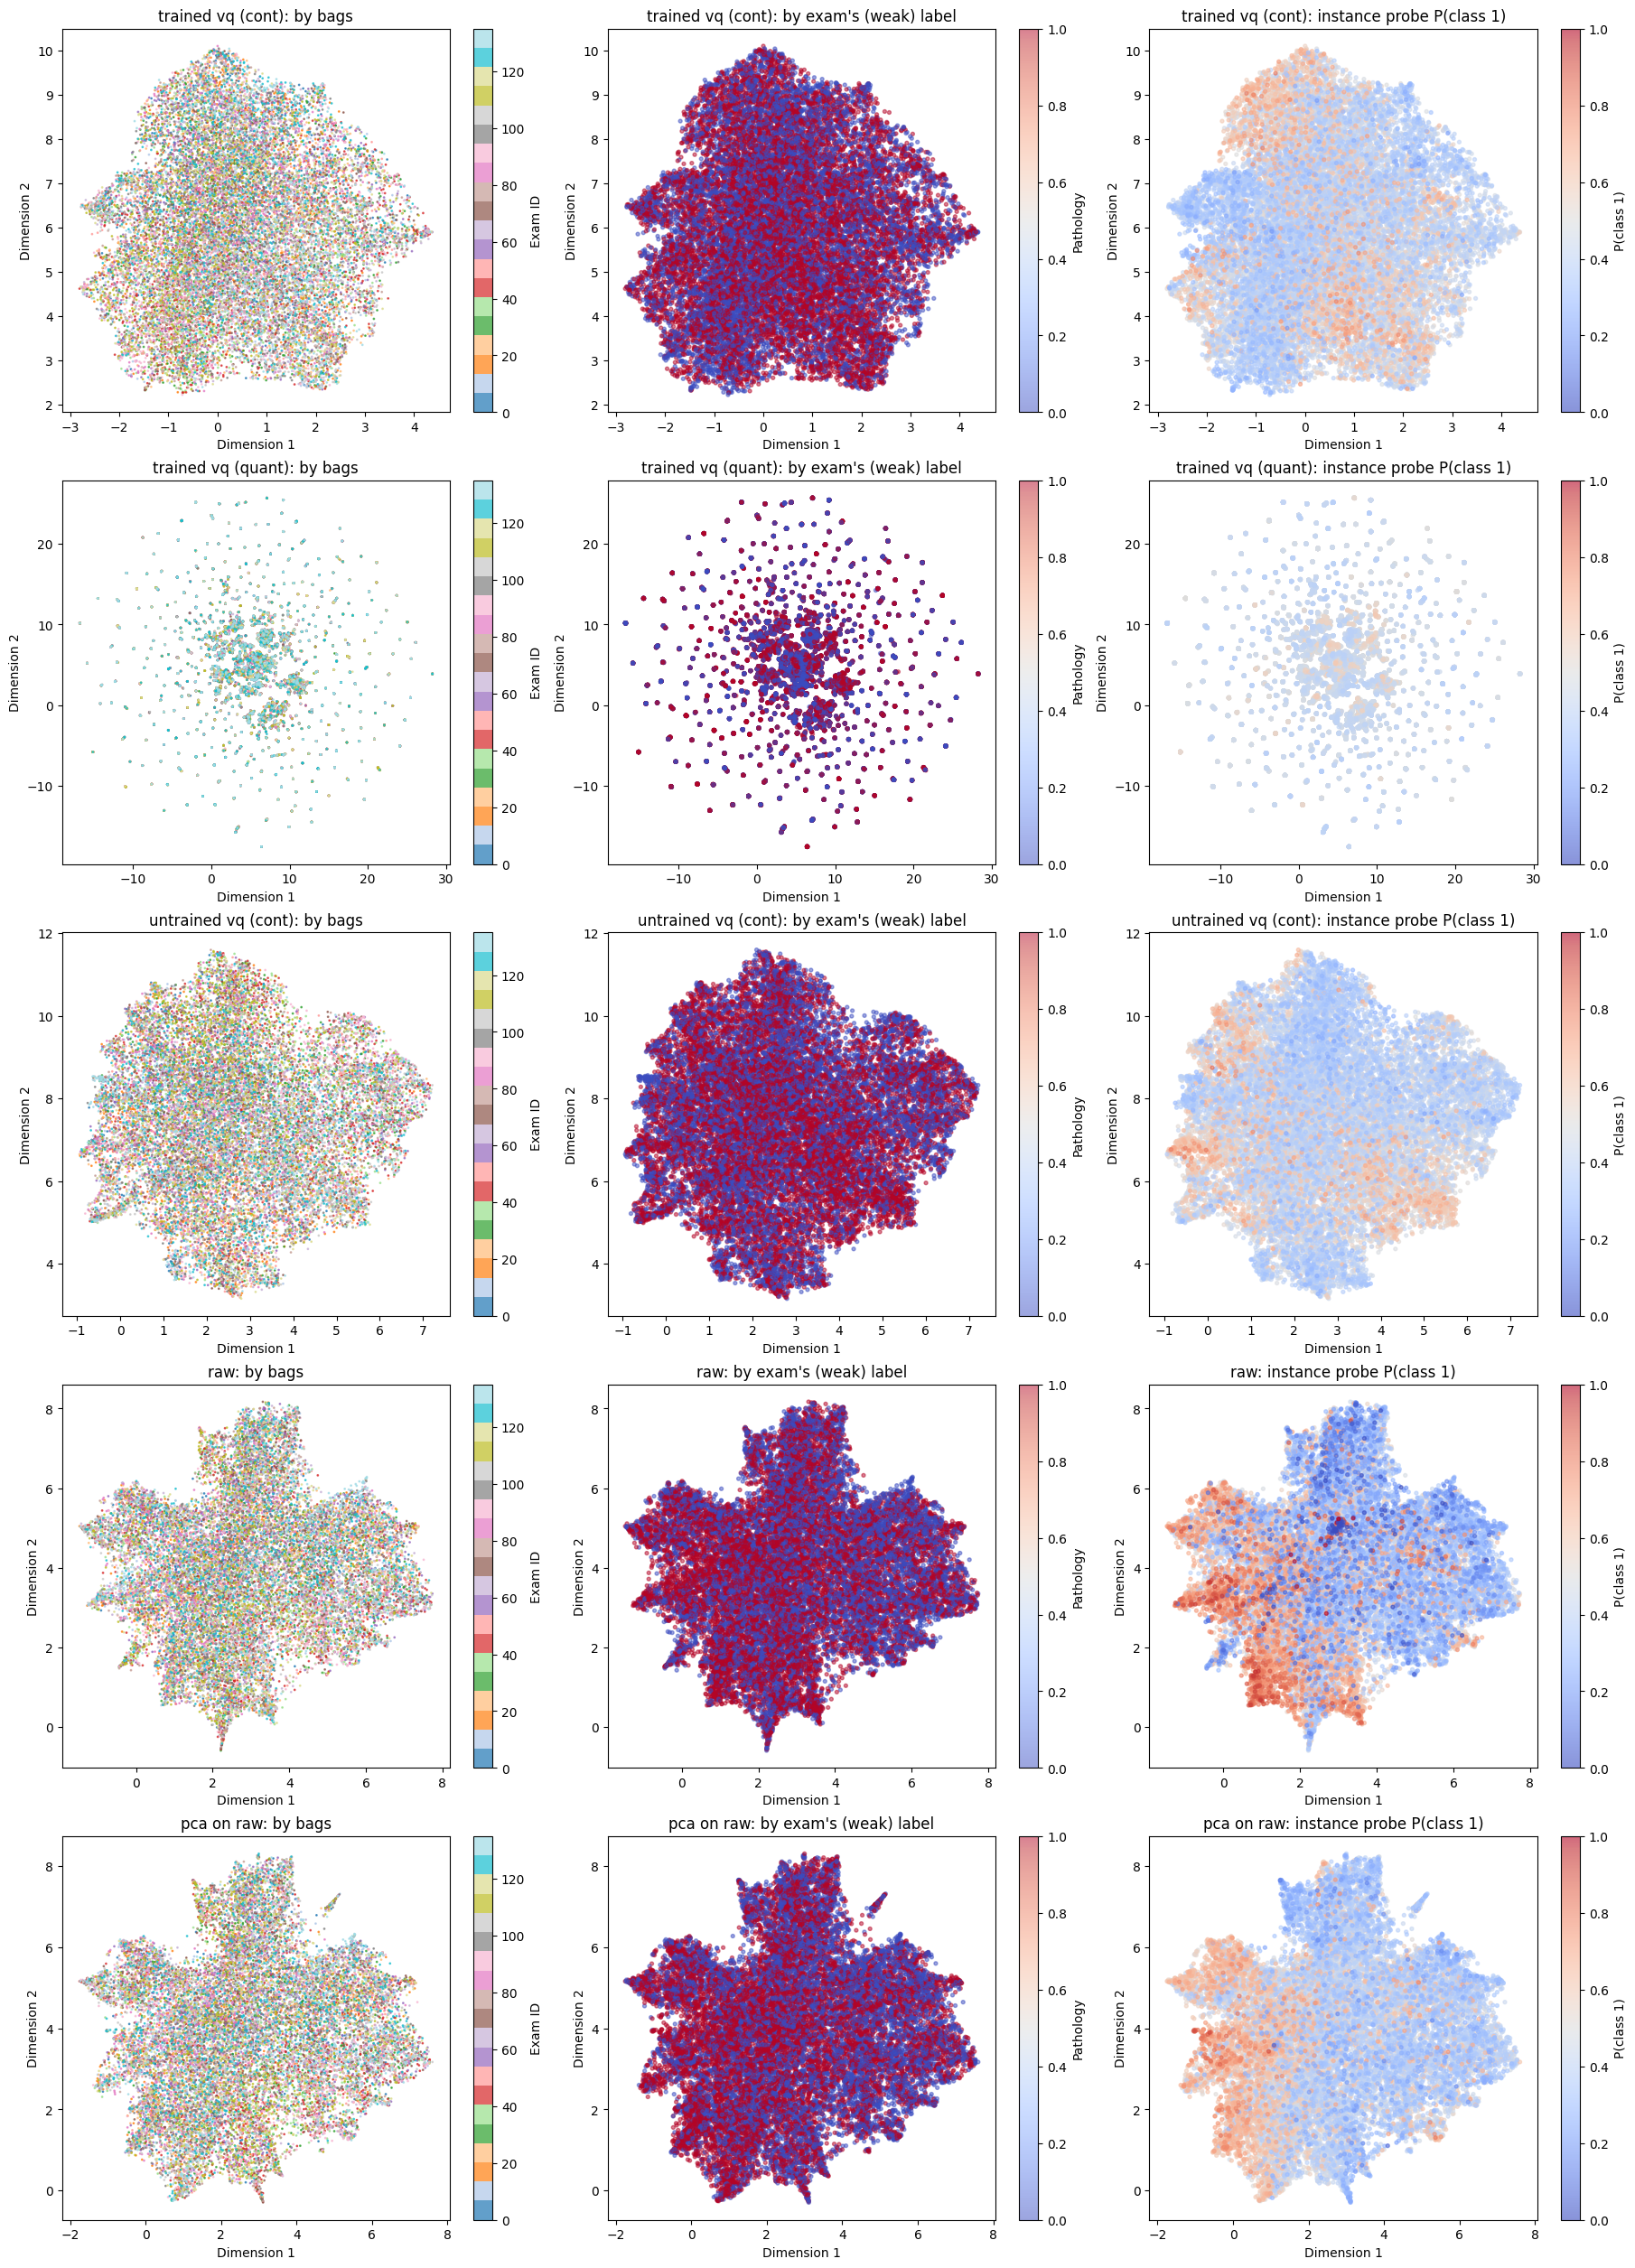

In [14]:
plot_embedding_votes(embeddings, artifacts, exam_ids, window_labels, rep_of=rep_of, mode="prob")
plt.show()

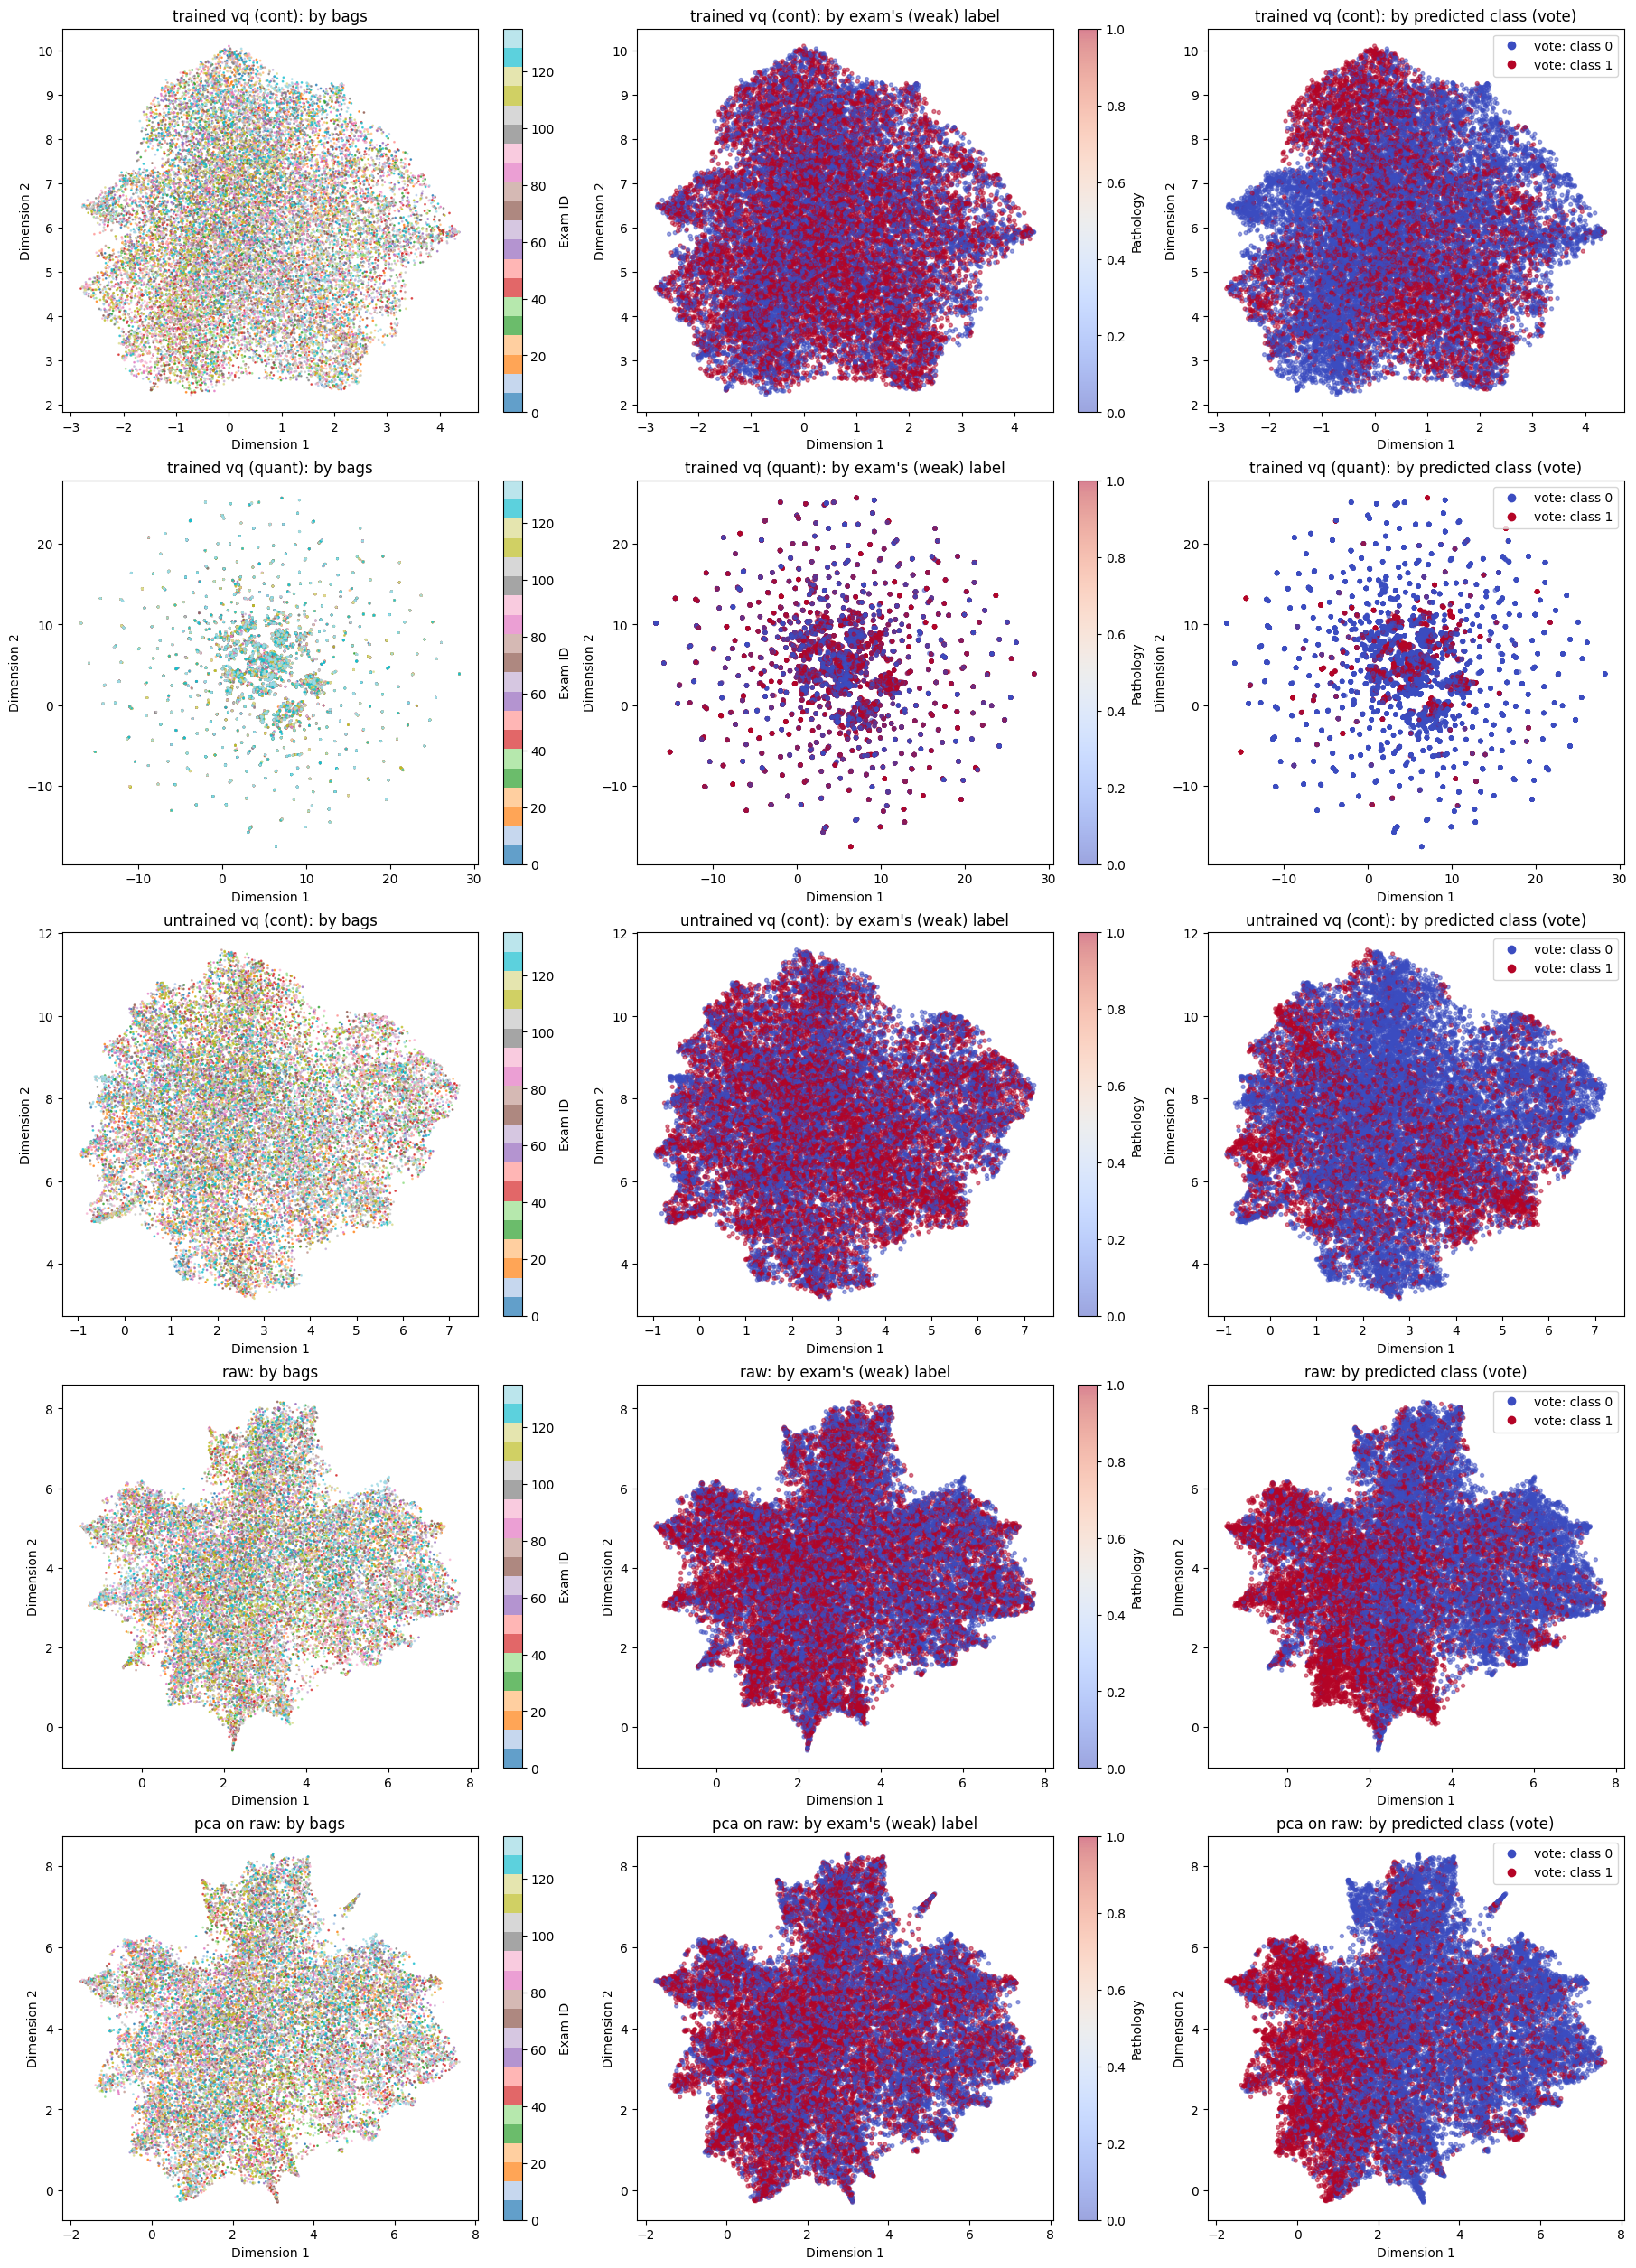

In [15]:
plot_embedding_votes(embeddings, artifacts, exam_ids, window_labels, rep_of=rep_of, mode="vote")
plt.show()